# Review of Unmatched Candidates — Čarađe

This notebook supports an independent review of candidates from the 15–31 March 2024 processing. It loads existing results and original waveform recordings. Review decisions are saved in a separate folder. The reference catalogue, picks and locations remain unchanged.

First, inspect all seven available stations. Record whether consistent arrivals are visible, whether the candidate may be a duplicate, and whether its location within the study area is sufficiently supported. The “confirmed” status represents the analyst’s assessment and requires an accompanying note. The modelled location is an initial estimate.

In [1]:
# Install the waveform library in the current Colab session.
%pip install -q obspy
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 1. Loading Candidates and Previous Review Decisions

In [8]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import timezone
from obspy import read, UTCDateTime

data_folder = Path("/content/drive/MyDrive/Caradje_CEME")
results_folder = data_folder / "results"
association_folder = results_folder / "march_associations"
validation_folder = results_folder / "candidate_validation"
decision_file = validation_folder / "review_decisions.csv"
channels = {
    "BRY": "EHZ", "UPM": "EHZ", "NKME": "EHZ", "HCY": "EHZ",
    "CEME": "HHZ", "KOME": "HHZ", "DRME": "HHZ",
}

events = pd.read_csv(
    results_folder / "march_15_31_event_candidates.csv",
    index_col="candidate_id",
)
events["origin_utc"] = pd.to_datetime(events["origin_utc"], format="mixed", utc=True)
matches = pd.read_csv(results_folder / "march_15_31_catalogue_matches.csv")
candidates = events.loc[~events.index.isin(matches["candidate_id"])].sort_values(
    "origin_utc"
).copy()

decision_columns = [
    "candidate_id", "signal_status", "study_area_status",
    "duplicate_of", "reviewed_stations", "notes", "reviewed_utc",
]
decisions = (
    pd.read_csv(decision_file, keep_default_na=False)
    if decision_file.is_file()
    else pd.DataFrame(columns=decision_columns)
)
print(f"Unmatched candidates loaded: {len(candidates)}")
print(f"Saved decisions: {len(decisions)}")
if len(candidates) != 116:
    print("Check the saved results: the last reported count was 116.")
display(candidates[["origin_utc", "stations", "rms_s", "latitude_deg", "longitude_deg"]])

Unmatched candidates loaded: 116
Saved decisions: 0


,origin_utc,stations,rms_s,latitude_deg,longitude_deg
candidate_id,,,,,
0,2024-03-15 00:29:42.796589487+00:00,5,0.185987,43.124294,18.549410
2,2024-03-15 02:26:40.059973111+00:00,5,0.518891,42.976226,18.922829
3,2024-03-15 03:13:28.184081507+00:00,6,0.452062,42.987038,18.648206
4,2024-03-15 03:16:34.853509355+00:00,6,0.432357,43.172985,18.445042
6,2024-03-15 04:43:27.349701676+00:00,5,0.407200,42.950356,18.674439
...,...,...,...,...,...
169,2024-03-30 13:23:22.206343007+00:00,5,0.445933,43.005755,18.880942
170,2024-03-30 14:27:22.934612653+00:00,5,0.005477,43.026375,18.382686
171,2024-03-30 14:58:02.643124203+00:00,5,0.466286,42.959833,18.695164


## 2. Candidate Selection and Waveform Review

Candidates are reviewed chronologically. Change only REVIEW_POSITION, starting from 0. The markers on the plots show the existing MAD picks. A quiet recording or an absent marker at one station is not, by itself, a reason to reject a candidate. Compare the available arrivals and wave packets across all stations.

The display covers 60 s before and 120 s after the estimated origin time. For a closer view, reduce BEFORE_S and AFTER_S.

/tmp/ipykernel_478/2520823288.py:17: UserWarning: Discarding nonzero nanoseconds in conversion.
  origin = UTCDateTime(event["origin_utc"].to_pydatetime())


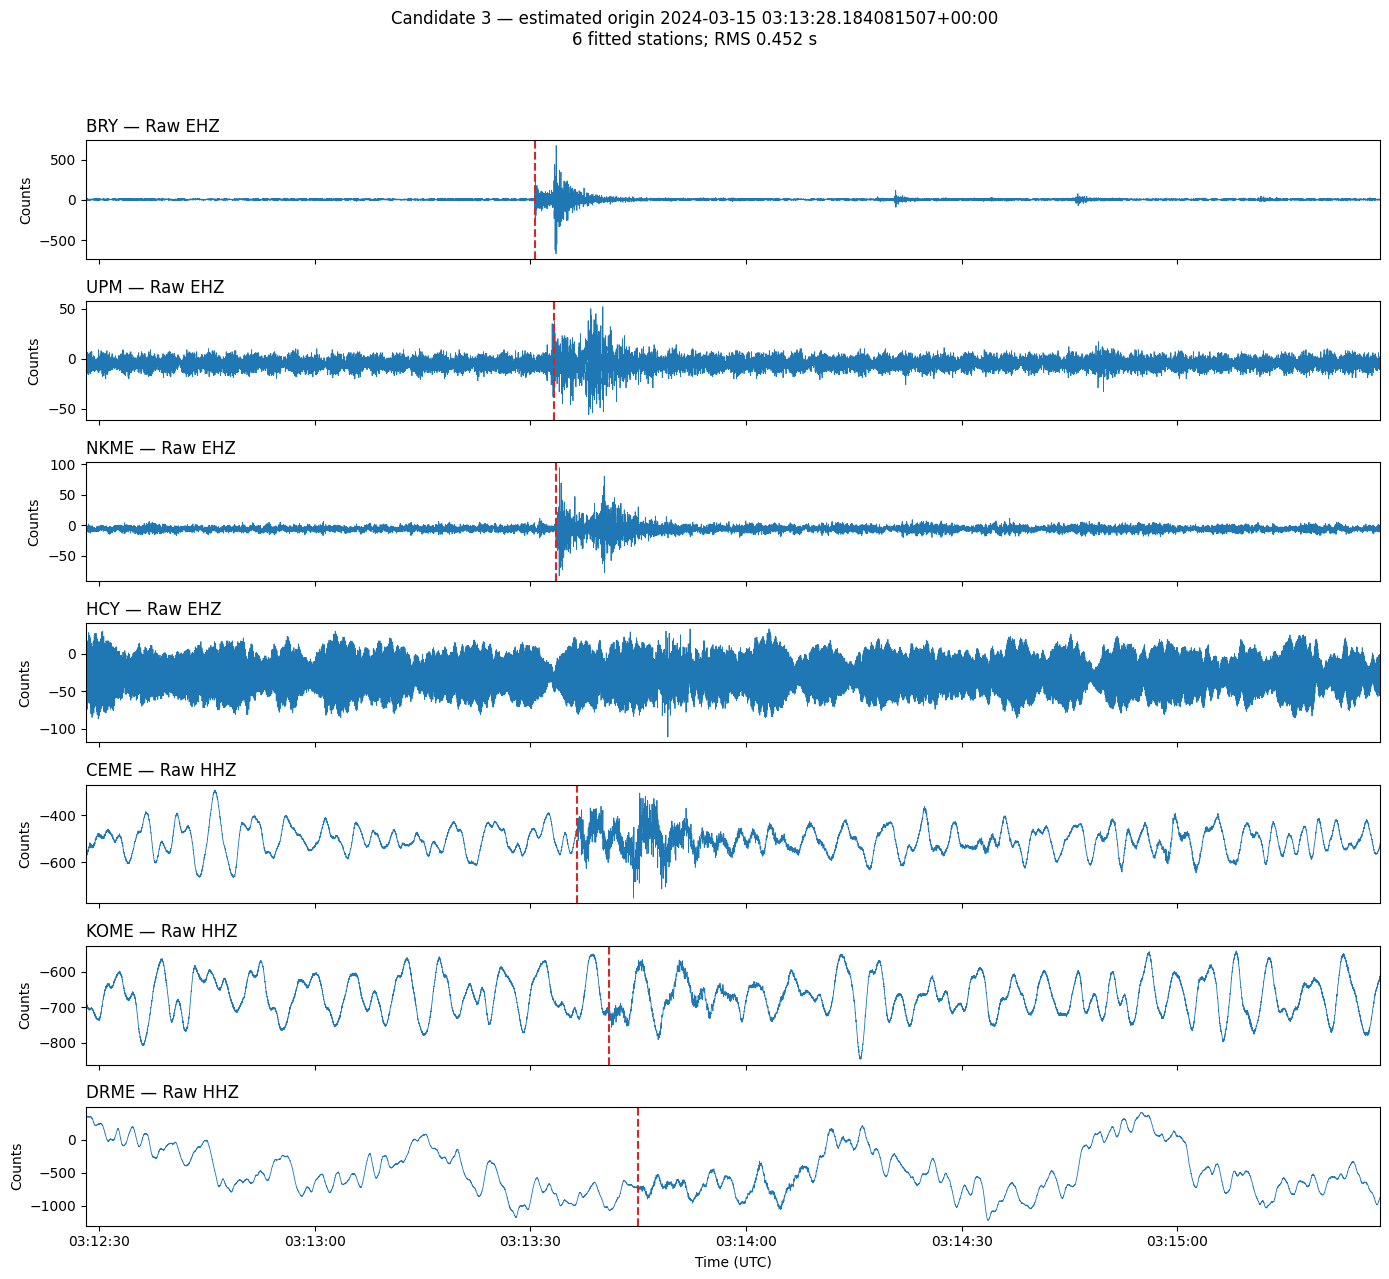

Candidate ID: 3
Available wa5eforms: BRY, UPM, NKME, HCY, CEME, KOME, DRME


,station,mad_p_utc
pick_id,,
2837,BRY,2024-03-15 03:13:30.570000+00:00
2839,UPM,2024-03-15 03:13:33.220000+00:00
2840,NKME,2024-03-15 03:13:33.590000+00:00
2842,CEME,2024-03-15 03:13:36.490000+00:00
2846,KOME,2024-03-15 03:13:40.890000+00:00
2848,DRME,2024-03-15 03:13:45+00:00


In [10]:
REVIEW_POSITION = 2
BEFORE_S = 60
AFTER_S = 120

candidate_id = candidates.index[REVIEW_POSITION]
event = candidates.loc[candidate_id]
processing_date = pd.Timestamp(event["processing_date"]).strftime("%Y-%m-%d")
input_picks = pd.read_csv(
    association_folder / f"association_picks_{processing_date}.csv",
    index_col="pick_id",
)
input_picks["mad_p_utc"] = pd.to_datetime(
    input_picks["mad_p_utc"], format="mixed", utc=True
)
selected_picks = input_picks.loc[json.loads(event["pick_ids"])].copy()

origin = UTCDateTime(event["origin_utc"].to_pydatetime())
start, end = origin - BEFORE_S, origin + AFTER_S
fig, axes = plt.subplots(7, 1, figsize=(14, 13), sharex=True)
available_stations = []

for ax, (station, channel) in zip(axes, channels.items()):
    drawn = False
    for date in pd.date_range(
        pd.Timestamp(start.datetime, tz="UTC").normalize(),
        pd.Timestamp(end.datetime, tz="UTC").normalize(), freq="D"
    ):
        path = data_folder / f"ME.{station}..{channel}.D.{date.year}.{date.dayofyear:03d}"
        if not path.is_file():
            continue
        waveform = read(str(path), format="MSEED", starttime=start, endtime=end)
        for trace in waveform:
            ax.plot(trace.times("matplotlib"), trace.data, linewidth=0.6)
            drawn = True

    station_picks = selected_picks.loc[
        selected_picks["station"].eq(station), "mad_p_utc"
    ]
    for pick in station_picks:
        ax.axvline(pick.to_pydatetime(), color="tab:red", linestyle="--")
    if drawn:
        available_stations.append(station)
    else:
        ax.text(0.02, 0.5, "Waveform unavailable", transform=ax.transAxes)
    ax.set_title(f"{station} — Raw {channel}", loc="left")
    ax.set_ylabel("Counts")

axes[-1].set_xlim(start.datetime, end.datetime)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S", tz=timezone.utc))
axes[-1].set_xlabel("Time (UTC)")
fig.suptitle(
    f"Candidate {candidate_id} — estimated origin {event['origin_utc']}\n"
    f"{int(event['stations'])} fitted stations; RMS {event['rms_s']:.3f} s"
)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()
print(f"Candidate ID: {candidate_id}")
print(f"Available wa5eforms: {', '.join(available_stations)}")
display(selected_picks.sort_values("mad_p_utc"))

## 3. Analyst Decision

Complete the fields, then run the cell. signal_status can be confirmed, rejected or uncertain. study_area_status can be supported, outside or uncertain. Confirming a seismic signal does not automatically confirm that it belongs to the study area.

For a duplicate, enter the other candidate’s ID in duplicate_of and explain the decision in notes. reviewed_stations should include only the stations you actually inspected. A new entry for the same ID replaces the previous decision in the separate review table.

In [ ]:
signal_status = "uncertain"
study_area_status = "uncertain"
duplicate_of = ""
reviewed_stations = ""
notes = ""

if signal_status not in {"confirmed", "rejected", "uncertain"}:
    raise ValueError("Invalid signal status.")
if study_area_status not in {"supported", "outside", "uncertain"}:
    raise ValueError("Invalid study-area status.")
if not notes.strip() or not reviewed_stations.strip():
    raise ValueError("Enter the reviewed stations and a reason for the decision.")

reviewed = {value.strip() for value in reviewed_stations.split(",") if value.strip()}
if not reviewed.issubset(set(available_stations)):
    raise ValueError("Reviewed stations must have available waveforms in this display.")
if signal_status == "confirmed" and len(reviewed) < 2:
    raise ValueError("Document the multi-station review before confirming the signal.")

new_decision = pd.DataFrame([{
    "candidate_id": candidate_id,
    "signal_status": signal_status,
    "study_area_status": study_area_status,
    "duplicate_of": str(duplicate_of),
    "reviewed_stations": ", ".join(sorted(reviewed)),
    "notes": notes,
    "reviewed_utc": pd.Timestamp.now(tz="UTC").isoformat(),
}])
decisions = pd.concat([
    decisions.loc[decisions["candidate_id"].astype(str).ne(str(candidate_id))],
    new_decision,
], ignore_index=True)

validation_folder.mkdir(parents=True, exist_ok=True)
temporary = decision_file.with_suffix(".tmp")
decisions.to_csv(temporary, index=False)
temporary.replace(decision_file)
print(f"Decision saved for candidate {candidate_id}: {decision_file}")